# Module 10 · Classifiers: Predicting Treatment Response from Gene Expression
### Two-class sequence · Lecture 1 (models) → Lecture 2 (evaluation)

**Biological question:** *Can pretreatment gene-expression measurements predict whether a tumor will respond to therapy?*

The data labels are **Responder (0)** and **Nonresponder (1)**.

This notebook builds on our earlier supervised (regression) and unsupervised (PCA/clustering) exercises. We briefly introduce **t-SNE and UMAP** as additional unsupervised visualization methods, then compare **Logistic Regression, Support Vector Machines (SVM), and Random Forests**. Lecture 2 assesses whether those predictions generalize.

**Data:** 600 simulated tumors × 80 simulated normalized expression measurements, with measured binary treatment response and a technical batch effect. The label is a treatment *outcome*, the nonresponder class is simulated to be less common, as is typical at the drug-trial stage.

**Learning Objectives**
1. Contrast PCA, t-SNE, and UMAP; explain why an unsupervised projection does not prove biological subtypes.
2. Explain and visualize Logistic Regression, RBF SVM (`C`, `gamma`), and Random Forest.
3. Perform stratified splitting, leakage-safe Pipelines, StratifiedKFold, and GridSearchCV.
4. Interpret TN / FP / FN / TP, sensitivity (recall), specificity, precision, F1, ROC-AUC, and average precision (PR) for a named positive class.
5. Select models and thresholds without using held-out test labels; separate predictive association from causal inference.

**Assignment:** Answer each **Predict** prompt *before* the next code cell, and **Explain** using its output. Edit the **_Your response here_** text in the existing Markdown cells—**do not add new cells**. Save your executed notebook and submit the GitHub links in Canvas.

**Pacing:** Lecture 1: Sections 0–5, including t-SNE/UMAP context. Lecture 2: Sections 6–10, including validation, threshold selection, ROC and PR curves.


**Name:** Sumathi Rani Manukonda  
**UTA ID:** 1002126624

## 0) Setup and reproducibility
This notebook uses NumPy, pandas, matplotlib, scipy, and scikit-learn. **UMAP is optional**, because it uses a separate package. In Colab, the setup cell installs it if necessary; outside Colab, the other exercises still run if UMAP is unavailable.

In [1]:
import sys, importlib.util, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if importlib.util.find_spec('umap') is None and IN_COLAB:
    print('Installing optional UMAP package in Colab (once per runtime)...')
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'umap-learn'])

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import expit
from pathlib import Path
from IPython.display import display
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve, classification_report
)

SEED = 42
BLUE, ORANGE, GREEN, PURPLE = '#0072B2', '#D55E00', '#009E73', '#CC79A7'
plt.rcParams.update({'figure.dpi':105,'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False})
OUT = Path('classifier_outputs'); OUT.mkdir(exist_ok=True)

def finish(filename):
    plt.tight_layout()
    plt.savefig(OUT / f'{filename}.png', dpi=150, bbox_inches='tight')
    plt.show()

def metrics(y_true, prediction):
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0,1]).ravel()
    return {'accuracy':accuracy_score(y_true,prediction),
            'balanced_accuracy':balanced_accuracy_score(y_true,prediction),
            'sensitivity / recall':recall_score(y_true,prediction,zero_division=0),
            'specificity':tn/(tn+fp),
            'precision':precision_score(y_true,prediction,zero_division=0),
            'F1':f1_score(y_true,prediction,zero_division=0),
            'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}

def show_cm(ax, truth, predictions, title):
    ConfusionMatrixDisplay.from_predictions(
        truth, predictions, labels=[0,1], display_labels=['Responder','Nonresponder'],
        cmap='Blues', colorbar=False, ax=ax, values_format='d')
    ax.set_title(title)

print('Python:',sys.version.split()[0], '| scikit-learn:',sklearn.__version__)

Python: 3.10.0rc2 | scikit-learn: 1.3.0


## 1) Define the problem: samples, features, and labels **(Slides 1-6)**

In unsupervised learning we explored expression structure *without* known labels. Here the scientific question is supervised: given expression and **observed treatment response** for training tumors, can we predict outcomes for new tumors?

The simulated dataset has **600 tumors × 80 expression features**, with **Responder (0)** more common than **Nonresponder (1)**. A **technical batch effect** changes some expression features but is not programmed to cause the treatment outcome. Batch is not an input to the classifiers.

We split the data into **TRAIN (60%)**, **VALIDATION (20%)**, and untouched **TEST (20%)** before modeling.

* **Stratification** *preserves the response proportions in each partition.*


**Predict (before running):** What label would an always-Responder baseline assign to every tumor? Could it have reasonably high **accuracy** while detecting **zero nonresponders**? What would its statistical **sensitivity** be for the nonresponder class?

**Your response:** **Prediction:** An always-Responder baseline assigns label 0 to every tumor. Because responders are the majority, its accuracy could be relatively high even though it misses every nonresponder. Sensitivity for the positive nonresponder class would be 0.


**After running:** The training split contains 280 responders and 80 nonresponders, so the always-Responder accuracy is 0.778 with sensitivity 0.000, matching the prediction. Stratification produced 360 training, 120 validation and 120 test tumors.

In [2]:
rng = np.random.default_rng(53)
n, p = 600, 80
program_a = rng.normal(size=n)
program_b = rng.normal(size=n)
batch = rng.integers(0,2,size=n)

# Simulated continuous normalized/log-like expression: NOT read counts.
gene_baselines = rng.normal(6.0,0.45,p)
X_all = gene_baselines + rng.normal(0, 0.95, size=(n,p))
X_all[:, 0:15] += 0.95*program_a[:,None]
X_all[:,15:30] += 0.90*program_b[:,None]
X_all[:,30:40] += 0.36*program_a[:,None] - 0.30*program_b[:,None]
X_all[:,45:70] += 2.00*batch[:,None]  # independent batch-driven expression

# Latent biology changes odds of nonresponse; neither response nor batch is a feature.
nonresponse_prob = expit(-2.25 + 1.60*program_a - 1.45*program_b
                        + 0.35*program_a*program_b)
y_all = rng.binomial(1, nonresponse_prob)
GENES = [f'Gene_{i+1:02d}' for i in range(p)]
ids = np.arange(n)

trainval_idx, test_idx = train_test_split(ids, test_size=0.20,
        stratify=y_all, random_state=SEED)
train_idx, val_idx = train_test_split(trainval_idx, test_size=0.25,
        stratify=y_all[trainval_idx], random_state=SEED)
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]
X_test, y_test = X_all[test_idx], y_all[test_idx]

assert len(set(train_idx)&set(test_idx)) == 0
assert len(set(train_idx)&set(val_idx)) == 0
print('TRAIN: ',X_train.shape, '  VAL: ',X_val.shape,'  TEST (do not inspect yet): ',X_test.shape)
print('Train class proportions:',pd.Series(y_train).map({0:'Responder',1:'Nonresponder'}).value_counts(normalize=True).round(3).to_dict())
display(pd.DataFrame(X_train[:4,:6], columns=GENES[:6]).round(2))
print('Always-Responder TRAINING accuracy:',round((y_train==0).mean(),3))
print('Always-Responder sensitivity for nonresponders:',0.0)

TRAIN:  (360, 80)   VAL:  (120, 80)   TEST (do not inspect yet):  (120, 80)
Train class proportions: {'Responder': 0.778, 'Nonresponder': 0.222}


,Gene_01,Gene_02,Gene_03,Gene_04,Gene_05,Gene_06
0,7.00,5.92,6.85,5.68,5.36,7.99
1,8.30,5.95,6.42,7.85,7.61,8.18
2,8.54,4.94,6.55,5.89,4.92,5.39
3,8.23,9.01,8.60,7.00,6.23,7.62


Always-Responder TRAINING accuracy: 0.778
Always-Responder sensitivity for nonresponders: 0.0


In [3]:
### Uncomment the line below to visulaize the dataframe with features and label data stitched together. ###
display(pd.DataFrame(X_train, columns=GENES).assign(Response=np.where(y_train == 1, "Nonresponder", "Responder"), Batch=np.asarray(batch)[train_idx]))

,Gene_01,Gene_02,Gene_03,Gene_04,Gene_05,Gene_06,Gene_07,Gene_08,Gene_09,Gene_10,...,Gene_73,Gene_74,Gene_75,Gene_76,Gene_77,Gene_78,Gene_79,Gene_80,Response,Batch
0,7.004987,5.919840,6.848830,5.679245,5.355597,7.994914,6.875984,7.989813,6.655276,5.908140,...,5.760716,5.936805,7.772154,6.869916,7.787910,5.931004,5.944981,4.616152,Responder,0
1,8.300304,5.950817,6.424523,7.849450,7.609624,8.180811,6.742865,7.613485,6.487845,6.571483,...,5.878862,6.388857,7.049336,8.805764,6.634344,5.055151,6.830811,5.436944,Responder,0
2,8.539952,4.941443,6.554839,5.894486,4.916984,5.389568,7.196361,5.061244,5.169256,3.632834,...,6.637483,8.208212,5.187800,5.587994,6.114678,5.206840,8.437442,7.156050,Responder,0
3,8.229490,9.011928,8.601539,7.003099,6.231945,7.617015,6.101111,5.842449,6.601932,6.971283,...,6.747729,5.081223,5.392759,7.018431,6.953676,6.189478,4.955344,4.826979,Responder,0
4,4.259742,5.504551,6.106807,7.017249,8.528607,5.622370,3.873707,6.439153,6.099389,7.394897,...,5.079320,5.757006,4.809115,7.336138,7.279333,7.644594,6.020960,7.170251,Responder,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,5.590103,5.552149,5.550824,6.735005,6.848968,6.797098,8.450509,5.644214,4.753232,6.161704,...,7.252346,8.355641,4.747582,5.772471,6.373836,7.021573,4.779336,5.379120,Responder,1
356,4.968327,5.295636,3.940069,4.763945,5.539707,6.094310,2.806301,4.853025,5.569890,6.223387,...,6.988586,6.920339,6.081640,5.827523,6.294522,8.276822,5.133164,6.613678,Nonresponder,0
357,6.411707,3.903739,3.642530,5.084382,4.897625,6.639723,6.322234,5.757820,6.166264,4.587898,...,4.340008,5.951507,5.537703,6.652434,6.293888,5.848887,4.624818,6.253855,Responder,1
358,6.590923,4.977492,6.030298,7.355501,5.111923,6.169170,5.701814,3.453398,6.281719,6.308020,...,4.794182,6.750777,5.057824,4.789377,7.994035,7.839602,4.878783,6.008822,Responder,1


## 2) Beyond PCA: three ways to visualize high-dimensional samples **(Slides 7-13)**

Last week we used **PCA** to summarize expression variation. This week we add two **nonlinear** approaches, *t-distributed Stochastic Neighbor Embedding (t-SNE)* and *Uniform Manifold Approximation and Projection (UMAP)*. All three compute coordinates using **expression features**, not response labels.

| Method | What it emphasizes | What the axes / distances mean | Important settings |
|---|---|---|---|
| **PCA** | Directions of greatest overall variance; linear combinations of genes | PCs have loadings; explained variance is meaningful. | Centering and scaling; number of PCs |
| **t-SNE** | Preserving similarity among nearby samples in a low-dimensional map | Axes have no gene-specific meaning; between-island distances and island sizes can mislead. | `perplexity` (roughly the size of a typical neighborhood); random seed |
| **UMAP** | Building and laying out a graph of nearby samples, often preserving some broader structure | Axes have no biological units; spacing and apparent gaps depend on settings. | `n_neighbors` (local vs broader structure); `min_dist` (packing density); random seed |

**Important interpretation limits:** These are *visualizations*. t-SNE and UMAP can make visually compelling islands even when there is no discrete biological subtype. Different settings can change the appearance of those islands. Seeing groups is **not** a classification accuracy measurement or evidence of an underlying mechanism. Later, our classifiers fit the original **80 expression features**, **not** the two plotted coordinates.

We will fit all three on the **TRAIN** samples, after training-only scaling, and *hide the response labels initially*. UMAP requires the optional `umap-learn` library; the code will skip it outside Colab if unavailable.

**Predict (before running):** If PCA, t-SNE, or UMAP shows two islands, does that prove they are Responders and Nonresponders? Suggest one *biological* source and one *technical* source of expression structure.

**Your response:** **Prediction:** Two islands would not establish that the groups represent response classes. Biological programs, such as proliferation, could produce expression structure, while processing batch could produce technical structure. The projections use expression alone and do not optimize response prediction.


**After running:** PCA retained 17.1% and 12.2% of standardized training variance in its first two axes, about 29.3% combined. The maps show structure without establishing a response-class interpretation, consistent with the prediction. UMAP was skipped outside Colab because its optional package was unavailable.

UMAP skipped outside Colab: install umap-learn if desired.


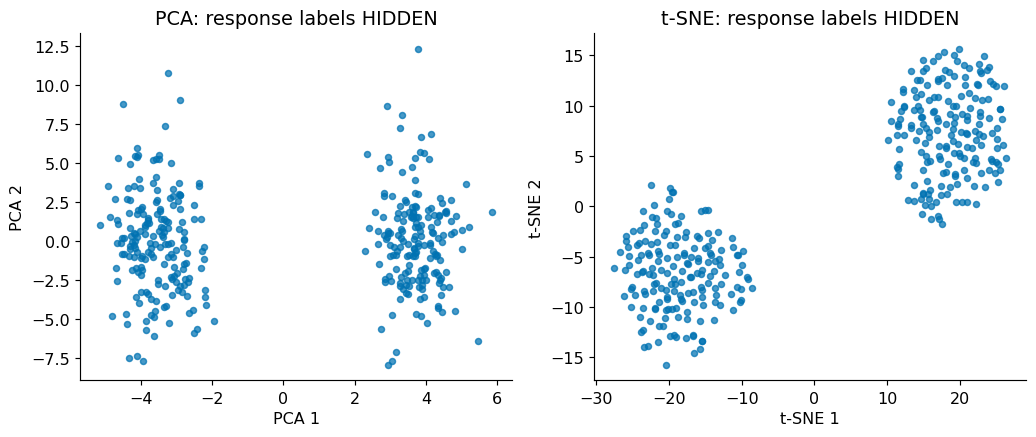

PCA variance explained by first two PCs: [0.171 0.122]


In [4]:
visual_scaler = StandardScaler().fit(X_train)  # TRAIN only
Z_train = visual_scaler.transform(X_train)
pca_vis = PCA(n_components=2, random_state=SEED).fit(Z_train)
pc_train = pca_vis.transform(Z_train)
ts_train = TSNE(n_components=2, init='pca', learning_rate='auto',
                perplexity=30, random_state=SEED).fit_transform(Z_train)
embeddings = [('PCA',pc_train), ('t-SNE',ts_train)]
try:
    import umap
    um_train = umap.UMAP(n_components=2,n_neighbors=20,min_dist=0.12,
                         random_state=SEED).fit_transform(Z_train)
    embeddings.insert(1, ('UMAP',um_train))
except ImportError:
    print('UMAP skipped outside Colab: install umap-learn if desired.')

fig,axs=plt.subplots(1,len(embeddings),figsize=(5*len(embeddings),4.3))
axs=np.atleast_1d(axs)
for ax,(name,xy) in zip(axs,embeddings):
    ax.scatter(xy[:,0],xy[:,1],s=17,color=BLUE,alpha=.72)
    ax.set(xlabel=f'{name} 1',ylabel=f'{name} 2',title=f'{name}: response labels HIDDEN')
finish('02_unlabeled_embeddings')
print('PCA variance explained by first two PCs:',np.round(pca_vis.explained_variance_ratio_,3))

**Explain (after running, still before revealing labels):** Describe one pattern that appears in the plots. Why does it remain scientifically ambiguous until we examine relevant sample metadata?

**Your response:** The unlabelled PCA map shows a broad separation along the first component, while t-SNE emphasizes local neighborhoods. Without metadata, a gap could reflect biological programs, processing batches, or a projection artifact. The coordinates alone do not identify which explanation is correct or establish response prediction.

### 2a) Why projection settings matter: same tumors, different maps

Changing t-SNE `perplexity` changes the effective neighborhood scale; changing UMAP `n_neighbors` changes how much local vs broader structure shapes its layout. These parameters **do not change the underlying gene-expression matrix**. Notice which apparent islands, shapes, and gaps persist across settings. A change in the picture is not evidence that the tumors changed.

**Predict (before running):** When we change a projection's neighborhood setting, will the locations, gaps, and apparent clusters necessarily remain unchanged? Can you use the size of a t-SNE island to estimate the number of tumors it contains?

**Your response:** **Prediction:** Changing neighborhood settings can change the locations, gaps and apparent groups, even though the same tumors and measurements are used. A t-SNE island’s area is not proportional to its sample count; the number of plotted observations must be counted directly.

**After running:** The two broad groups persist, but their orientation, shape and spacing change between perplexity 10 and 60. This agrees with the prediction that apparent geometry need not be invariant. Island area was not used as a sample-count estimate.

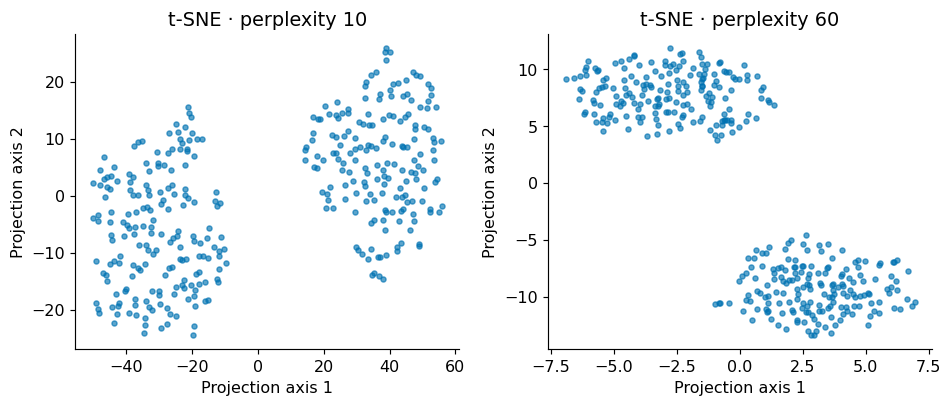

In [5]:
# Illustrate sensitivity to two neighborhood choices; TRAIN samples only.
projections=[]
for perp in (10,60):
    xy=TSNE(n_components=2,init='pca',learning_rate='auto',
            perplexity=perp,random_state=SEED).fit_transform(Z_train)
    projections.append((f't-SNE · perplexity {perp}',xy))
try:
    import umap
    for neighbors in (8,60):
        xy=umap.UMAP(n_components=2,n_neighbors=neighbors,min_dist=.12,
                     random_state=SEED).fit_transform(Z_train)
        projections.append((f'UMAP · neighbors {neighbors}',xy))
except ImportError:
    pass
fig,axs=plt.subplots(1,len(projections),figsize=(4.6*len(projections),4.0))
for ax,(name,xy) in zip(np.atleast_1d(axs),projections):
    ax.scatter(xy[:,0],xy[:,1],s=12,alpha=.64,color=BLUE)
    ax.set(title=name,xlabel='Projection axis 1',ylabel='Projection axis 2')
finish('02_projection_settings')

**Explain (after running):** Describe one change in the *appearance* of the same tumors when a projection setting changes. Why does this make it risky to interpret every plotted island as a distinct tumor subtype? What sort of independent information would help you assess the biology?

**Your response:** Both t-SNE settings preserve two broad groups, but at perplexity 10 they appear as taller, more dispersed clouds separated horizontally; at perplexity 60 they become more compact, oblique bands with different spacing and orientation. The 360 training tumors and their 80 measurements have not changed. These differences mean an island’s shape, area or gap is not direct evidence for a subtype. Technical metadata, independently measured biological markers and replication in a separate cohort would help distinguish the explanations. UMAP was skipped by the supplied optional-package fallback, so I do not infer a UMAP-specific result.

### 2b) Reveal response labels — then ask what actually drives structure **(Slide 14)**

Now color *the same training embeddings* by observed nonresponse status. We can also color PCA by simulated **technical batch**. This batch information is supplied **only for interpretation**; it is never used as a predictor.

**Predict:** Will every visible structure line up with the nonresponse label? If PCA separates batches more clearly than Nonresponders and Responders, is PCA necessarily wrong?

**Your response:** **Prediction:** I do not expect every visible pattern to follow response status. PCA maximizes expression variance, so clearer batch separation would mean that technical variation is prominent, not that PCA failed at its mathematical objective.

**After running:** The PCA batch colors separate much more clearly than the response colors, while responders and nonresponders occur within both broad groups. This supports the prediction that dominant expression variation can be technical.

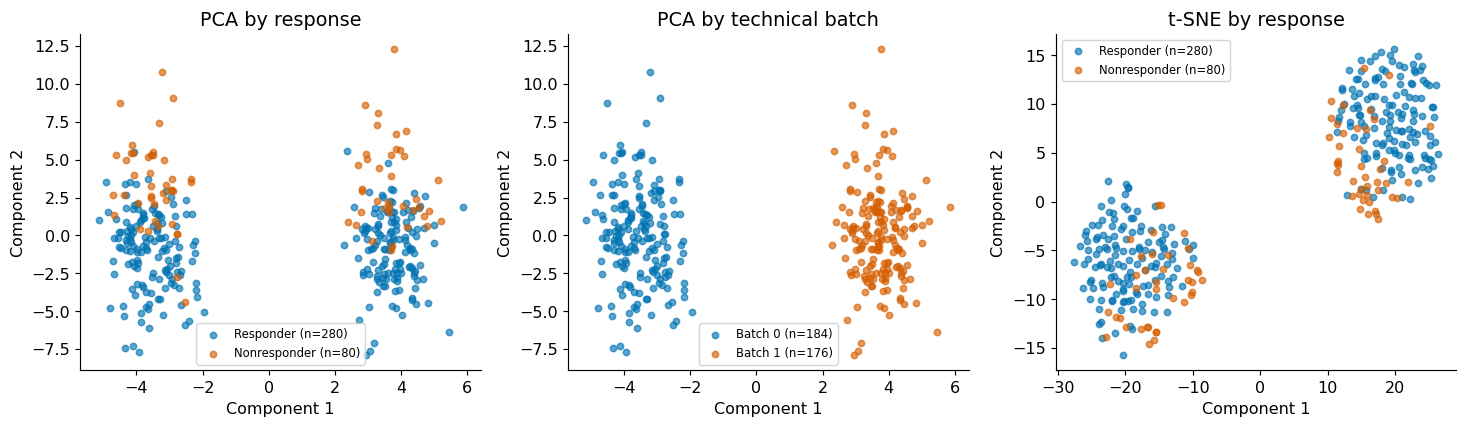

In [6]:
plots=[('PCA by response',pc_train,y_train,('Responder','Nonresponder')),
       ('PCA by technical batch',pc_train,batch[train_idx],('Batch 0','Batch 1'))]
plots += [(f'{name} by response',xy,y_train,('Responder','Nonresponder'))
          for name,xy in embeddings if name!='PCA']
fig,axs=plt.subplots(1,len(plots),figsize=(4.7*len(plots),4.2))
axs=np.atleast_1d(axs)
for ax,(title,xy,labels,names) in zip(axs,plots):
    for lab,col in [(0,BLUE),(1,ORANGE)]:
        mask=(labels==lab)
        ax.scatter(xy[mask,0],xy[mask,1],s=19,alpha=.64,color=col,label=f'{names[lab]} (n={mask.sum()})')
    ax.legend(fontsize=8)
    ax.set(xlabel='Component 1',ylabel='Component 2',title=title)
finish('02_metadata_reveal')

**Explain:** Which metadata variable appears more closely related to the main PCA structure: **response class** or **technical batch**? How does this connect to our earlier question about whether unsupervised clusters represent biologically meaningful subtypes? Can a supervised classifier still extract nonresponse-related signal that is *not* the dominant source of variance?

**Your response:** Technical batch corresponds more closely to the main PCA separation than response class. Responders and nonresponders overlap within that structure, whereas the batch colors separate along the dominant direction. This illustrates why an unsupervised cluster may reflect how samples were processed rather than a biological subtype. A supervised classifier can still learn weaker expression patterns associated with nonresponse because it optimizes a label-related objective rather than total expression variance. Batch is excluded as an explicit predictor, although expression features can still encode batch.

## 3) Classifier family 1: Logistic Regression **(Slides 15-18)**

Despite the name, **logistic regression is a classifier**. For a binary response, it computes a *linear score* from expression features, then converts that score to a predicted probability using the sigmoid:

$$ z = b + \sum_j w_j x_j, \qquad P(\mathrm{Nonresponder}\mid X)=\frac{1}{1+e^{-z}}. $$

A **decision threshold**, often `0.50`, converts that score into a Nonresponder (1) / Responder (0) prediction. The `C` hyperparameter is the **inverse strength of regularization**: smaller `C` means stronger regularization. Here, as in lecture, we can visualize a 2-gene model; the full predictor later uses all 80 genes.

**Predict:** If `P(nonresponse) = 0.41`, which class will be predicted with threshold `0.50`? With threshold `0.25`? If we increase `Gene_01` and its coefficient is positive, which direction does predicted probability of nonresponse move?

**Your response:** **Prediction:** At probability 0.41, the prediction is Responder (0) at threshold 0.50 and Nonresponder (1) at threshold 0.25. Holding other features fixed, increasing a gene with a positive coefficient increases the linear score, nonresponse odds and predicted probability.

**After running:** The fitted sigmoid increases with its score. Gene_01 has a positive coefficient (0.713) and Gene_16 a negative coefficient (−1.022), agreeing with the directional prediction. The 0.41 threshold example follows directly from comparing that fixed probability with the two cutoffs.

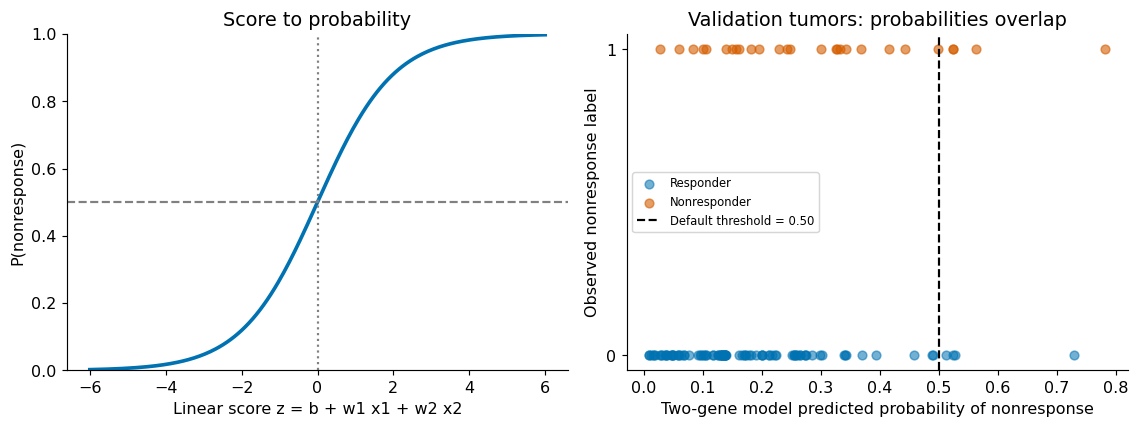

Intercept: -1.621   Standardized gene coefficients: {'Gene_01': 0.713, 'Gene_16': -1.022}


In [7]:
TWO = [0,15]   # Gene_01 and Gene_16 (one from each latent expression program)
X2_tr, X2_val = X_train[:,TWO], X_val[:,TWO]
logit2 = make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=2000))
logit2.fit(X2_tr,y_train)
b=float(logit2.named_steps['logisticregression'].intercept_[0])
w=logit2.named_steps['logisticregression'].coef_[0]
z=np.linspace(-6,6,250)
fig,axs=plt.subplots(1,2,figsize=(11,4.2))
axs[0].plot(z,expit(z),color=BLUE,linewidth=2.5)
axs[0].axhline(.5,color='gray',linestyle='--'); axs[0].axvline(0,color='gray',linestyle=':')
axs[0].set(xlabel='Linear score z = b + w1 x1 + w2 x2', ylabel='P(nonresponse)',title='Score to probability',ylim=(0,1))
p2=logit2.predict_proba(X2_val)[:,1]
axs[1].scatter(p2[y_val==0],np.zeros((y_val==0).sum()),color=BLUE,alpha=.55,label='Responder')
axs[1].scatter(p2[y_val==1],np.ones((y_val==1).sum()),color=ORANGE,alpha=.60,label='Nonresponder')
axs[1].axvline(.5,color='black',ls='--',label='Default threshold = 0.50')
axs[1].set(xlabel='Two-gene model predicted probability of nonresponse',ylabel='Observed nonresponse label',yticks=[0,1],title='Validation tumors: probabilities overlap')
axs[1].legend(fontsize=8)
finish('03_logistic_probabilities')
print('Intercept:',round(b,3),'  Standardized gene coefficients:',dict(zip([GENES[j] for j in TWO],np.round(w,3))))

**Explain:** Read the fitted coefficients in the output. Which of these genes increases predicted nonresponse *odds*, holding the other fixed? Are these coefficients causal effects? Why can predicted probabilities overlap even when the classifier has learned a useful signal?

**Your response:** Gene_01 has a positive standardized coefficient of 0.713, so increasing its expression increases estimated nonresponse odds while Gene_16 is held fixed. Gene_16 has coefficient −1.022 and therefore decreases those odds; the fitted intercept is −1.621. A one-training-SD increase corresponds approximately to odds multipliers exp(0.713) = 2.04 and exp(−1.022) = 0.36, respectively. These are conditional fitted associations, not causal effects. The response is stochastic, the two genes measure the latent programs imperfectly, and most expression features are omitted from this illustration, so useful signal can coexist with substantial overlap between observed classes.

# Changing the threshold does not retrain the classifier **(Slide 19)**

**Predict:** Before moving the threshold from 0.50 to 0.20, predict what will happen to sensitivity, specificity, and the number of false positives.

**Explain:** Move the slider and examine the results. Why do the confusion matrix and performance metrics change even though the logistic regression model has not been retrained? Does lowering the threshold necessarily decrease precision?

**Prediction:** Lowering the threshold from 0.50 to 0.20 should increase or preserve sensitivity and false positives, while decreasing or preserving specificity. Probabilities and fitted coefficients will remain fixed. Precision may decline, but its direction depends on the newly flagged observations.

**Explanation after running:** At threshold 0.50 the two-gene model had TN = 89, FP = 4, FN = 23 and TP = 4: sensitivity 0.148, specificity 0.957, precision 0.500 and F1 0.229. At 0.20 it had TN = 60, FP = 33, FN = 11 and TP = 16: sensitivity 0.593, specificity 0.645, precision 0.327 and F1 0.421. This matches the predicted sensitivity–specificity tradeoff. The fitted model produces the same probabilities; only their conversion into class labels changes. Precision fell in this run because the additional flagged tumors included many responders, but a decrease is not guaranteed for every dataset.

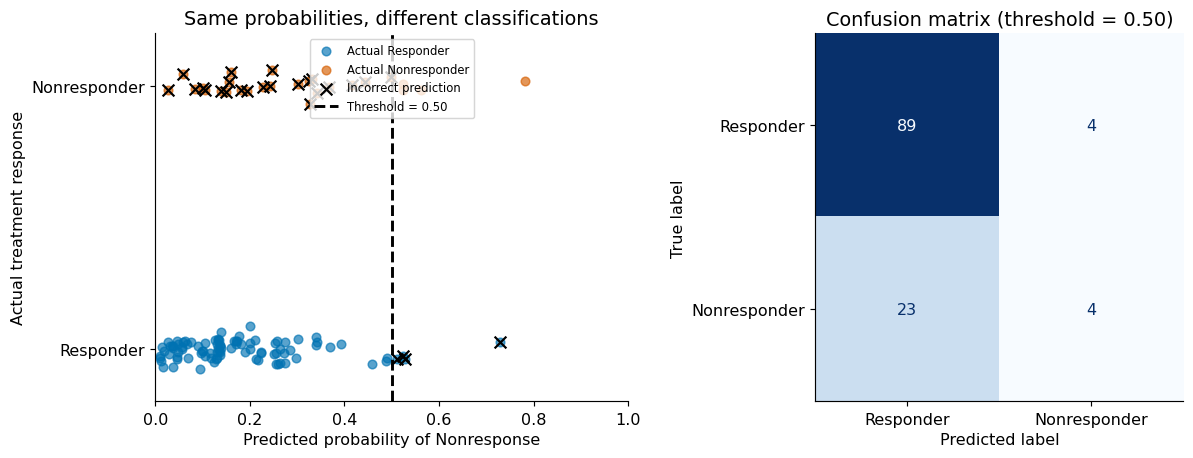

,Accuracy,Sensitivity,Specificity,Precision,F1
0,0.775,0.148,0.957,0.5,0.229


TN=89   FP=4   FN=23   TP=4
Model coefficients and predicted probabilities are unchanged.


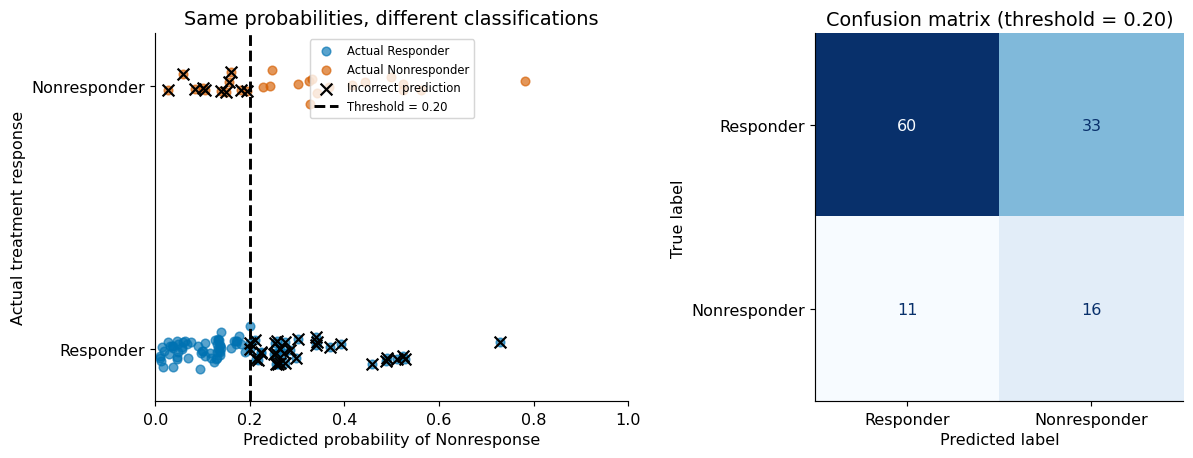

,Accuracy,Sensitivity,Specificity,Precision,F1
0,0.633,0.593,0.645,0.327,0.421


TN=60   FP=33   FN=11   TP=16
Model coefficients and predicted probabilities are unchanged.


In [8]:
# Explicit threshold comparisons also display in static GitHub viewers.

# Fixed validation probabilities from the trained logistic regression
# p2 was calculated in the preceding cell.
jitter = np.random.default_rng(42).normal(0, 0.04, len(y_val))

def explore_threshold(threshold):

    # Change classifications WITHOUT retraining the model
    predictions = (p2 >= threshold).astype(int)
    m = metrics(y_val, predictions)

    fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))

    # LEFT: Predicted probabilities for each tumor
    for actual, label, color in [
        (0, "Actual Responder", BLUE),
        (1, "Actual Nonresponder", ORANGE)
    ]:
        mask = y_val == actual
        axs[0].scatter(
            p2[mask], y_val[mask] + jitter[mask],
            color=color, alpha=0.65, s=35, label=label
        )

    # Highlight incorrectly classified tumors
    wrong = predictions != y_val
    axs[0].scatter(
        p2[wrong], y_val[wrong] + jitter[wrong],
        marker="x", color="black", s=65,
        label="Incorrect prediction"
    )

    # Decision threshold
    axs[0].axvline(threshold, color="black", linestyle="--",
                   linewidth=2, label=f"Threshold = {threshold:.2f}")

    axs[0].set(
        xlabel="Predicted probability of Nonresponse",
        ylabel="Actual treatment response",
        yticks=[0, 1],
        yticklabels=["Responder", "Nonresponder"],
        xlim=(0, 1),
        ylim=(-0.2, 1.2),
        title="Same probabilities, different classifications"
    )
    axs[0].legend(fontsize=8, loc="upper center")

    # RIGHT: Updated confusion matrix
    show_cm(axs[1], y_val, predictions,
            f"Confusion matrix (threshold = {threshold:.2f})")

    plt.tight_layout()
    plt.show()

    # Updated performance metrics
    display(pd.DataFrame([{
        "Accuracy": m["accuracy"],
        "Sensitivity": m["sensitivity / recall"],
        "Specificity": m["specificity"],
        "Precision": m["precision"],
        "F1": m["F1"]
    }]).round(3))

    print(f"TN={m['TN']}   FP={m['FP']}   FN={m['FN']}   TP={m['TP']}")
    print("Model coefficients and predicted probabilities are unchanged.")
explore_threshold(0.50)
explore_threshold(0.20)


## 4) Classifier family 2: Support Vector Machine (SVM) **(Slides 20-22)**

An **SVM** tries to separate labeled classes by a decision boundary with a large margin. A Radial Basis Function (RBF) kernel permits **nonlinear boundaries** without explicitly constructing all transformed coordinates.

The two hyperparameters emphasized in lecture are:

- **`C`**: how strongly to penalize classification errors. Small `C` = more regularization; large `C` = stronger pressure to fit training labels.
- **`gamma`**: how local a training point's influence is in the **RBF kernel**. Small `gamma` = smoother, broad influence; large `gamma` = narrower, more flexible influence.

Below we show Logistic Regression, RBF SVM, and Random Forest **using the same two genes**. These 2D diagrams explain shapes, **not** final 80-gene model selection.

**Predict:** Which family should have a *straight* decision boundary? Which can bend around individual groups? Will increasing `gamma` and `C` always improve predictions on **validation** samples?

**Your response:** **Prediction:** Logistic regression should have a straight boundary in the two-gene plane. An RBF SVM can form curved boundaries and a Random Forest can form irregular, axis-aligned regions. Increasing C and gamma can fit training observations more closely but need not improve validation prediction.

**After running:** The plotted Logistic Regression boundary is straight, the SVM boundary is curved and the forest boundary has stepped regions. Two-gene TRAIN/VALIDATION F1 values were 0.411/0.229, 0.355/0.129 and 0.641/0.167, respectively. More detailed training boundaries did not imply better validation F1.

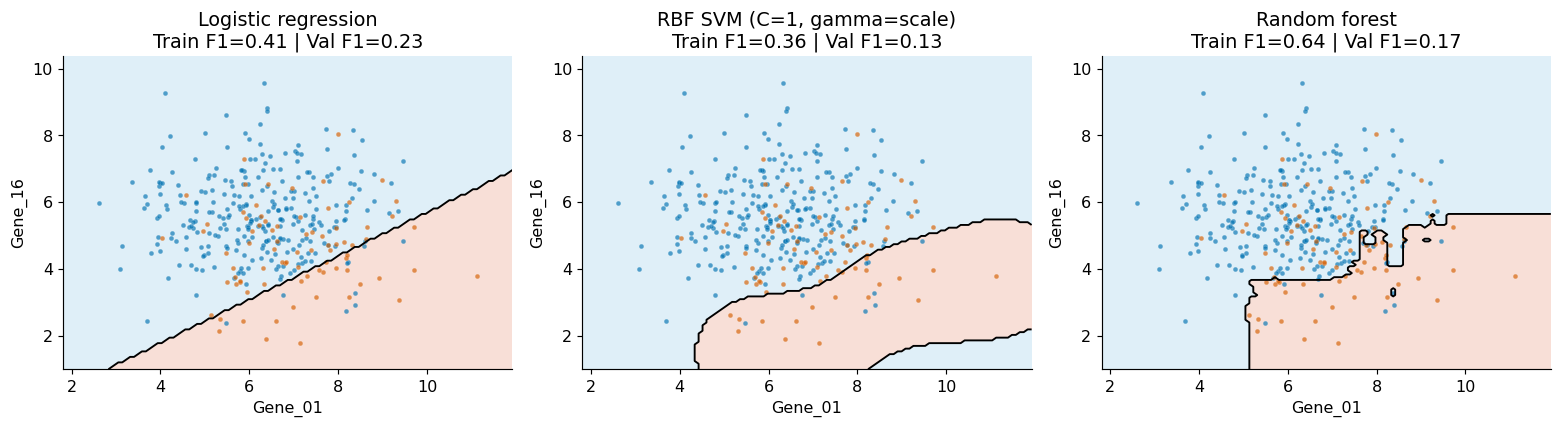

,Classifier,TRAIN F1,VALIDATION F1
0,Logistic regression,0.411,0.229
1,"RBF SVM (C=1, gamma=scale)",0.355,0.129
2,Random forest,0.641,0.167


In [9]:
from matplotlib.colors import ListedColormap

def boundary_panel(ax,model,name):
    model.fit(X2_tr,y_train)
    margin=0.8
    x1=np.linspace(X2_tr[:,0].min()-margin,X2_tr[:,0].max()+margin,115)
    x2=np.linspace(X2_tr[:,1].min()-margin,X2_tr[:,1].max()+margin,115)
    xx,yy=np.meshgrid(x1,x2)
    xy=np.c_[xx.ravel(),yy.ravel()]
    classes=model.predict(xy).reshape(xx.shape)
    ax.contourf(xx,yy,classes,levels=[-.5,.5,1.5],colors=['#D8EBF7','#F7D8CD'],alpha=.8)
    ax.contour(xx,yy,classes,levels=[.5],colors='black',linewidths=1.3)
    for cls,color in [(0,BLUE),(1,ORANGE)]:
        mask=y_train==cls
        ax.scatter(X2_tr[mask,0],X2_tr[mask,1],s=11,alpha=.65,
                   c=color,edgecolors='white',linewidths=.15)
    tr_f1=f1_score(y_train,model.predict(X2_tr),zero_division=0)
    vl_f1=f1_score(y_val,model.predict(X2_val),zero_division=0)
    ax.set(xlabel='Gene_01',ylabel='Gene_16',title=f'{name}\nTrain F1={tr_f1:.2f} | Val F1={vl_f1:.2f}')
    return tr_f1,vl_f1

boundaries={
 'Logistic regression':make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000)),
 'RBF SVM (C=1, gamma=scale)':make_pipeline(StandardScaler(),SVC(kernel='rbf',C=1,gamma='scale',probability=True,random_state=SEED)),
 'Random forest':RandomForestClassifier(n_estimators=100,max_depth=6,min_samples_leaf=3,random_state=SEED,n_jobs=-1)
}
fig,axs=plt.subplots(1,3,figsize=(15,4.2))
boundary_results=[]
for ax,(name,model) in zip(axs,boundaries.items()):
    train_f1,val_f1=boundary_panel(ax,model,name)
    boundary_results.append((name,train_f1,val_f1))
finish('04_three_classifier_boundaries')
display(pd.DataFrame(boundary_results,columns=['Classifier','TRAIN F1','VALIDATION F1']).round(3))

### 4a) Experiment with `C` and `gamma`
Compare **four RBF SVM settings** with the same training/validation data. The dotted question from lecture is: *when does extra flexibility turn into overfitting?*

**Predict:** Between `C=0.1, gamma=0.03` and `C=50, gamma=5`, which is more likely to fit isolated training observations? Which will necessarily have the better validation F1?

**Your response:** **Prediction:** C = 50 and gamma = 5 should be more likely to fit isolated observations because errors are penalized strongly and each point has a local influence. Neither setting is guaranteed to have better validation F1; greater flexibility may fit noise.

**After running:** The high-C/high-gamma panel is the most local, with training F1 0.708 and validation F1 0.263. It did better than the C = 0.1, gamma = 0.03 model, which had both F1 values 0.000, but retained a substantial gap. The observed comparison is compatible with the prediction; it does not imply the higher-flexibility setting must win on a different sample.

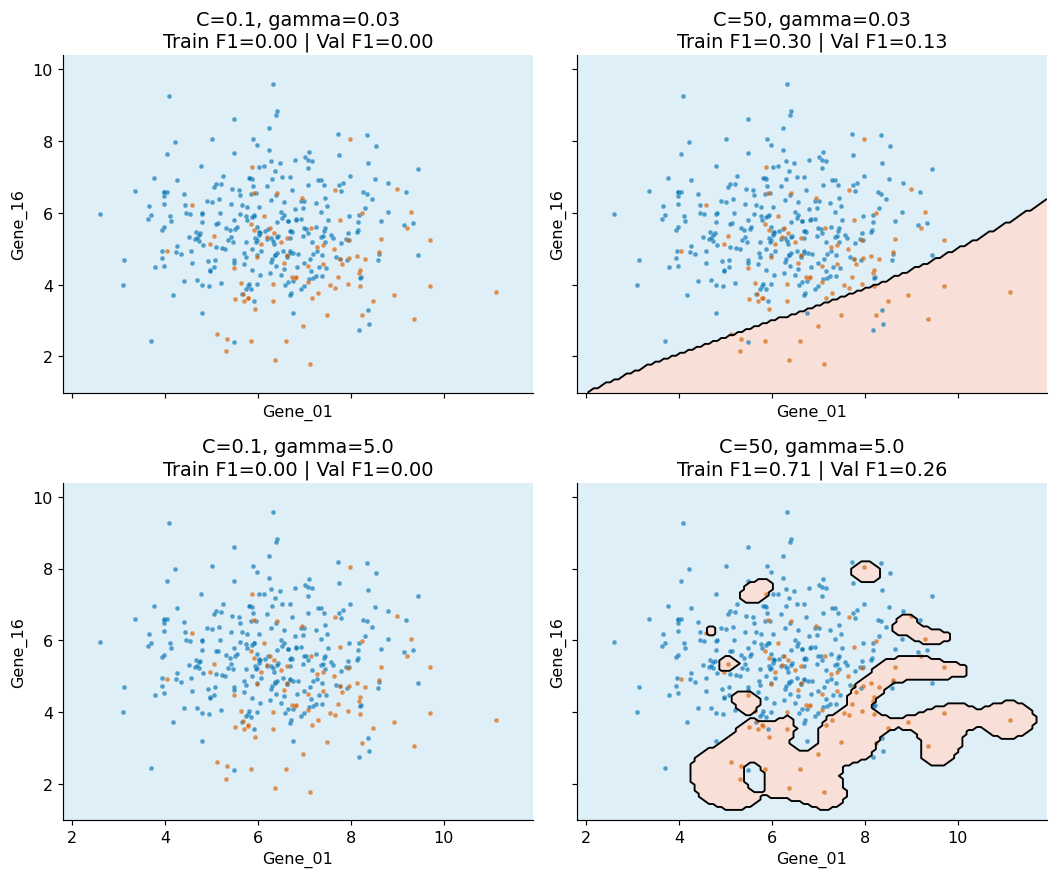

,C,gamma,TRAIN F1,VALIDATION F1
0,0.1,0.03,0.000,0.000
1,50.0,0.03,0.300,0.133
2,0.1,5.00,0.000,0.000
3,50.0,5.00,0.708,0.263


In [10]:
# C and gamma are hyperparameters supplied before training, NOT learned coefficients.
settings=[(.1,.03), (50,.03), (.1,5.0), (50,5.0)]
fig,axs=plt.subplots(2,2,figsize=(10.2,8.5),sharex=True,sharey=True)
rows=[]
for ax,(C,gamma) in zip(axs.flat,settings):
    model=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=C,gamma=gamma,
                       probability=True,random_state=SEED))
    tr,vl=boundary_panel(ax,model,f'C={C}, gamma={gamma}')
    rows.append({'C':C,'gamma':gamma,'TRAIN F1':tr,'VALIDATION F1':vl})
finish('04_svm_c_gamma')
display(pd.DataFrame(rows).round(3))

**Explain:** Point to the panel with the most flexible/complex boundary. Does its training F1 look like a reliable estimate of generalization? Explain one visible instance in which allowing more complex decision boundaries helps or hurts validation performance.

**Your response:** The C = 50, gamma = 5 panel has the most local and irregular boundary, including regions around isolated observations. Its training F1 is not an independent estimate of generalization because the same labels shaped that boundary. The numerical training–validation comparison above quantifies how the additional flexibility affects unseen validation tumors.

With C = 50 and gamma = 5, training F1 was 0.708 but validation F1 was only 0.263. At fixed C = 50, increasing gamma from 0.03 to 5 improved validation F1 from 0.133 to 0.263, while increasing training F1 from 0.300 to 0.708. Thus added flexibility helped validation in this comparison but left a large generalization gap; it did not make training F1 trustworthy. Both C = 0.1 settings predicted no positives at the default decision rule and had F1 = 0.000. The experiment does not support a claim that complexity always hurts or always helps.

## 5) Classifier family 3: Random Forest **(Slides 23-25)**

A **Random Forest** aggregates many decision trees. Each tree uses a **bootstrap sample** of the training observations and considers a random subset of features at a split. Its class probability is typically the **average class probability from the trees**, so it can also be thresholded.

The *impurity-based feature importance* scores (Gini index) indicate which features the trees used to reduce impurity, **not** proof of biological causation. Correlated expression measurements may split importance among themselves.

#### Visualize the first few layers of the first tree in the Random Forest

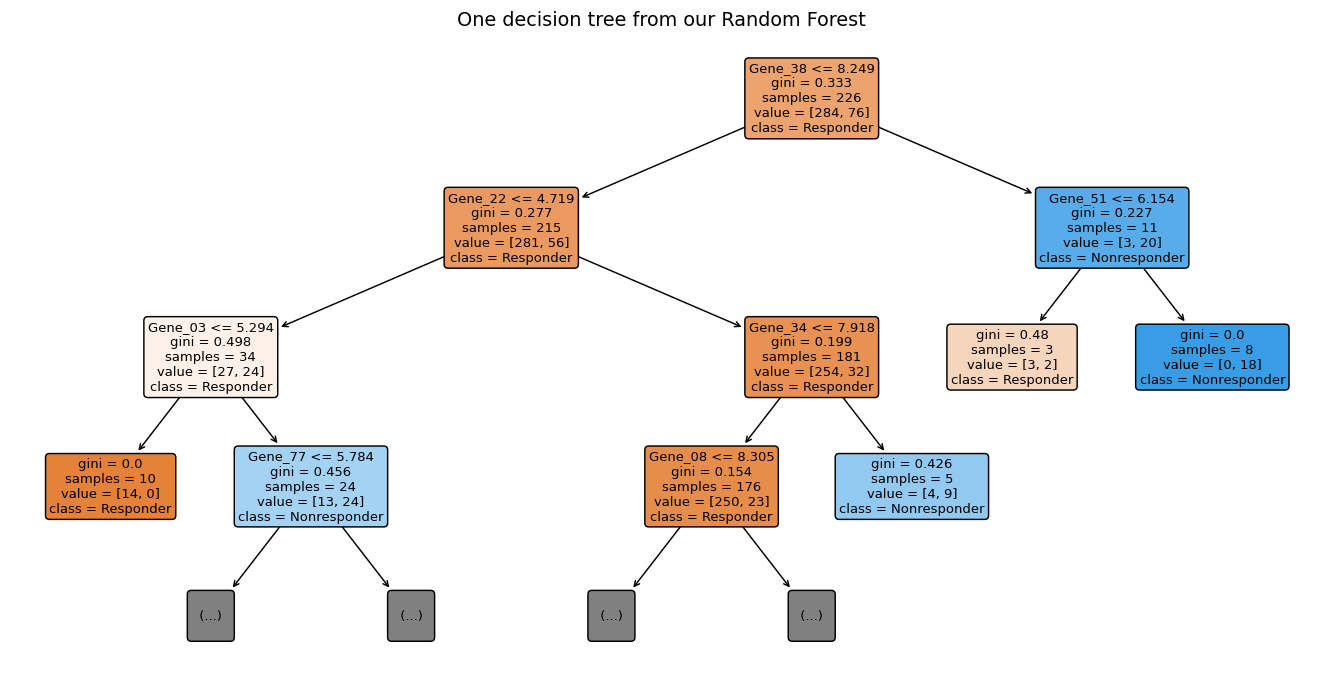

In [11]:
from sklearn.tree import plot_tree

rf_demo=RandomForestClassifier(n_estimators=150,max_depth=7,min_samples_leaf=3,random_state=SEED,n_jobs=-1)
rf_demo.fit(X_train,y_train)

plt.figure(figsize=(16, 8))

plot_tree(
    rf_demo.estimators_[0],
    feature_names=GENES,
    class_names=["Responder", "Nonresponder"],
    max_depth=3,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("One decision tree from our Random Forest")
plt.show()

**Predict:** Why might a Random Forest perform better on new samples than a single unpruned decision tree?

**Explain:** Run the cell below and examine the Random Forest feature-importance plot. Which genes contribute most to classification? Does high feature importance demonstrate that these genes cause treatment nonresponse? Why or why not?

**Your response:** **Prediction:** Averaging many trees should reduce the variance of a single unpruned tree. Bootstrap sampling and random feature subsets reduce similarity between the trees, although a forest can still overfit or perform poorly on shifted data.

**After running:** The forest’s training F1 was 0.904, but validation F1 was 0.432, showing that ensemble averaging does not eliminate a generalization gap. The most important features were Gene_12 (0.0558), Gene_06 (0.0474), Gene_27 (0.0378) and Gene_13 (0.0377), followed by Gene_16 (0.0288). These genes come from the simulated latent-program regions and are useful fitted predictors. Impurity importance summarizes split-based reductions in training impurity, can be biased, and can distribute importance among correlated genes. It neither identifies a causal mechanism nor establishes that changing these genes would alter treatment response. No single-tree validation comparison was run here, so the prediction about forests is a variance argument, not a measured superiority claim in this notebook.

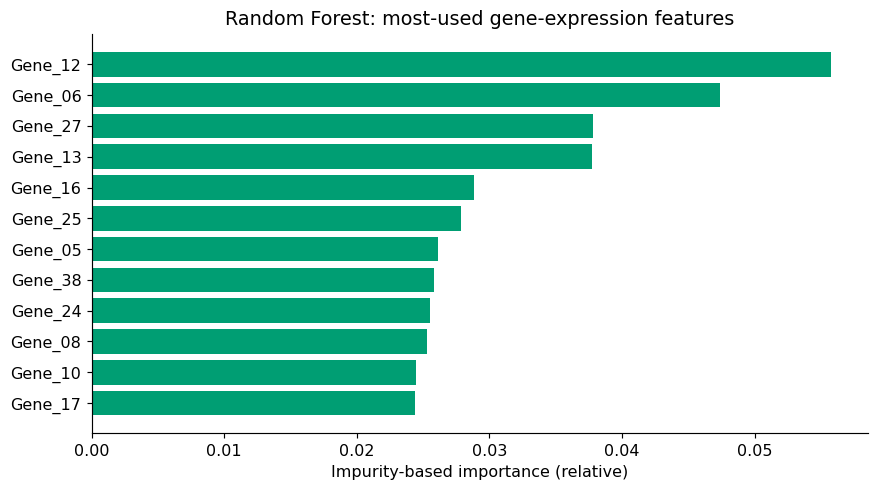

Random Forest training F1: 0.904
Random Forest validation F1: 0.432


Top genes: [('Gene_12', 0.0558), ('Gene_06', 0.0474), ('Gene_27', 0.0378), ('Gene_13', 0.0377), ('Gene_16', 0.0288), ('Gene_25', 0.0278), ('Gene_05', 0.0261), ('Gene_38', 0.0258), ('Gene_24', 0.0255), ('Gene_08', 0.0253), ('Gene_10', 0.0245), ('Gene_17', 0.0244)]


In [12]:
important=np.argsort(rf_demo.feature_importances_)[-12:][::-1]
fig,ax=plt.subplots(figsize=(8.5,4.8))
ax.barh([GENES[i] for i in important[::-1]],rf_demo.feature_importances_[important[::-1]],color=GREEN)
ax.set(xlabel='Impurity-based importance (relative)',title='Random Forest: most-used gene-expression features')
finish('05_random_forest_features')
print('Random Forest training F1:',round(f1_score(y_train,rf_demo.predict(X_train)),3))
print('Random Forest validation F1:',round(f1_score(y_val,rf_demo.predict(X_val)),3))
print("Top genes:", [(GENES[i], round(float(rf_demo.feature_importances_[i]),4)) for i in important])


---
# **Lecture 2 · Training, Tuning, and Evaluating Classifiers**

**Checkpoint:** You have seen how three classifier families produce predictions. Now ask whether those predictions are reliable on *new tumors*. In Lecture 2 we choose hyperparameters with training-only cross-validation, choose a decision threshold with validation data, and assess the frozen model once on the test set.

**Recall:** Positive class = **Nonresponder (1)**; **sensitivity** = TP / (TP + FN) for nonresponders.

## 6) Leakage-safe Pipelines, cross-validation and grid search

This section follows the workflow from lecture:

1. Keep the **held-out TEST** samples completely untouched.
2. On the **TRAIN** samples, a scikit-learn **Pipeline** fits preprocessing inside each cross-validation training fold, then learns a classifier.
3. **StratifiedKFold** keeps the positive/negative proportions approximately balanced across folds.
4. **GridSearchCV** evaluates predefined hyperparameter combinations and selects the best **cross-validation** score; we compare the three families.
5. The chosen model is evaluated on **VALIDATION** data to choose an operating threshold; only then do we use the TEST samples **once**.

Why `scoring='average_precision'` instead of just accuracy? In this example, the nonresponse class is less common and **ranking true nonresponders above responder tumors** matters. Average precision summarizes the precision–recall curve, **without fixing a 0.50 threshold**. We will also report ROC-AUC and classification counts.

**Predict:** What leakage occurs if you standardize **all** samples *before splitting*, or use test-set F1 to decide which `C` and `gamma` to use? Is `C` a model parameter or hyperparameter?

**Your response:** **Prediction:** Scaling all samples leaks held-out feature-distribution information into preprocessing, even without directly using response labels. Selecting C or gamma using test F1 leaks test outcomes into model selection. C is a hyperparameter specified before fitting; fitted coefficients or support vectors are learned from the training data.

**After running:** The scaler is inside each Logistic Regression/SVM pipeline, GridSearchCV uses only X_train and y_train, and the final test set is excluded from selection. This implements the separation anticipated in the prediction. The leakage alternatives were identified conceptually rather than deliberately executed.

In [13]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
models={
 'Logistic regression':Pipeline([('scale',StandardScaler()),
                                  ('clf',LogisticRegression(max_iter=2500,random_state=SEED))]),
 'RBF SVM':Pipeline([('scale',StandardScaler()),
                      ('clf',SVC(kernel='rbf',probability=True,random_state=SEED))]),
 'Random Forest':Pipeline([('clf',RandomForestClassifier(random_state=SEED,n_jobs=1))])
}
parameter_grids={
 'Logistic regression':{'clf__C':[.1,1,10]},
 'RBF SVM':{'clf__C':[.1,1,10],'clf__gamma':[.001,'scale',.1]},
 'Random Forest':{'clf__n_estimators':[100,200],'clf__min_samples_leaf':[2,6]}
}

searches={}; cv_rows=[]
for name,pipe in models.items():
    grid=GridSearchCV(pipe,parameter_grids[name],scoring='average_precision',
                      cv=cv,n_jobs=1,refit=True)
    grid.fit(X_train,y_train) # scaler is fitted anew *inside each fold*.
    searches[name]=grid
    cv_rows.append({'Classifier':name,'Mean CV AP':grid.best_score_,
                    'Best hyperparameters':str(grid.best_params_)})
cv_table=pd.DataFrame(cv_rows).sort_values('Mean CV AP',ascending=False).reset_index(drop=True)
display(cv_table.round(3))
chosen_name=cv_table.iloc[0]['Classifier']
chosen_model=searches[chosen_name].best_estimator_
print('Selected by TRAIN-only cross-validated average precision:',chosen_name)
print('Training-only fitted model:',chosen_model)
cv_table.to_csv(OUT/'cv_model_selection.csv',index=False)

,Classifier,Mean CV AP,Best hyperparameters
0,RBF SVM,0.792,"{'clf__C': 0.1, 'clf__gamma': 0.001}"
1,Random Forest,0.742,"{'clf__min_samples_leaf': 6, 'clf__n_estimator..."
2,Logistic regression,0.704,{'clf__C': 0.1}


Selected by TRAIN-only cross-validated average precision: RBF SVM
Training-only fitted model: Pipeline(steps=[('scale', StandardScaler()),
                ('clf',
                 SVC(C=0.1, gamma=0.001, probability=True, random_state=42))])


### 6a) Visualize the SVM grid search

A grid is an explicit, finite search over `C × gamma`. The grid uses gamma = 0.001, `scale`, and 0.1. The `scale` setting automatically computes gamma = 1 / (number of features × variance); with 80 standardized expression features, it is approximately **0.0125**.

Colors below show **mean cross-validated average precision on training folds**; these scores are *not* test performance. A setting is not guaranteed to be optimal just because it wins a small grid.

**Predict:** If the same data are reused to test hundreds of hyperparameter combinations, why might even the best cross-validation score be optimistic? What should remain untouched?

**Your response:** **Prediction:** The maximum of many noisy CV estimates can be optimistic because some settings benefit from chance favorable folds. A final test set must remain untouched by model, hyperparameter and threshold selection. Nested CV or external validation would provide additional protection against selection bias.

**After running:** The finite grid selected SVM C = 0.1, gamma = 0.001 at mean CV AP 0.792. The selection score is distinct from independent performance; the final test evaluation was kept outside the grid. No hundreds-setting search was run, so the selection-bias prediction was not tested as a separate experiment.

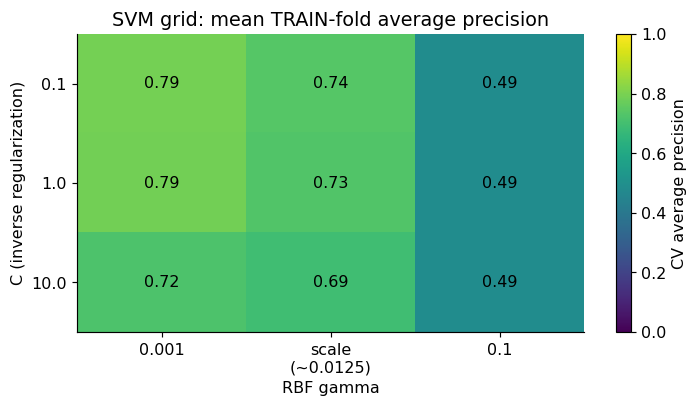

In [14]:
svm_cv=pd.DataFrame(searches['RBF SVM'].cv_results_)
svm_cv['C']=svm_cv['param_clf__C'].astype(float)
svm_cv['gamma']=svm_cv['param_clf__gamma'].astype(str)
pivot=(svm_cv.pivot(index='C',columns='gamma',values='mean_test_score')
       .reindex(columns=['0.001','scale','0.1']))
fig,ax=plt.subplots(figsize=(7.0,4.0))
im=ax.imshow(pivot.to_numpy(),cmap='viridis',aspect='auto',vmin=0,vmax=1)
# 'scale' is approximately 1 / 80 = 0.0125 after StandardScaler.
ax.set_xticks(range(len(pivot.columns)),['0.001','scale\n(~0.0125)','0.1'])
ax.set_yticks(range(len(pivot.index)),pivot.index)
ax.set(xlabel='RBF gamma',ylabel='C (inverse regularization)',
       title='SVM grid: mean TRAIN-fold average precision')
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        val=pivot.iloc[i,j]
        ax.text(j,i,f'{val:.2f}',ha='center',va='center',
                color='white' if val<.48 else 'black',fontsize=11)
fig.colorbar(im,ax=ax,label='CV average precision')
finish('06_svm_grid_search')

**Explain:** Which SVM `C`/`gamma` setting achieved the highest mean CV average precision? Which model family won overall? Does that prove the same ranking must hold for a new population or a future laboratory?

**Your response:** The best SVM setting was C = 0.1 and gamma = 0.001, with mean five-fold training CV average precision 0.792. RBF SVM won the family comparison; Random Forest had 0.742 using 200 trees and minimum leaf size 6, and Logistic Regression had 0.704 using C = 0.1. These are finite-grid results on one training population, not universal model rankings. A new population, laboratory, prevalence or feature distribution could change the ranking; external evaluation is necessary.

## 7) Classification errors: sensitivity, specificity, precision and F1

From this point forward, evaluate the cross-validation-selected classifier on the **VALIDATION** samples only. **Nonresponder = positive** (`1`).

| | Predicted Responder (`0`) | Predicted Nonresponder (`1`) |
|---|---:|---:|
| **Actually Responder (`0`)** | **TN** = true negative | **FP** = false positive (false alarm) |
| **Actually Nonresponder (`1`)** | **FN** = false negative (missed nonresponse) | **TP** = true positive |

\[ \mathrm{Sensitivity/Recall}=\frac{TP}{TP+FN},\qquad \mathrm{Specificity}=\frac{TN}{TN+FP} \]
\[ \mathrm{Precision}=\frac{TP}{TP+FP},\qquad F_1=\frac{2\,\mathrm{Precision}\,\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}. \]

A nonresponder incorrectly predicted responder (**FN**) could receive ineffective treatment if this were a legitimate clinical tool. A responder tumor incorrectly predicted nonresponse (**FP**) could be denied an effective treatment. **Neither error has a universal cost**. F1 is a teaching objective here, not a clinical recommendation.

**Predict:** If we **lower** the threshold from `0.50` to `0.20`, will sensitivity tend to rise or fall? What happens to the number of false positives? Must *precision* decrease in every possible dataset?

**Your response:** **Prediction:** Lowering the threshold should increase or preserve sensitivity and increase or preserve the false-positive count; specificity should decrease or stay unchanged. Precision often falls when more responders are flagged, but it is not mathematically required to fall: it depends on the class mix among the newly flagged tumors.

**After running:** For the selected 80-gene SVM, lowering the threshold from 0.50 to 0.20 raised sensitivity from 0.593 to 0.778 and false positives from 13 to 22, while specificity fell from 0.860 to 0.763. Precision fell from 0.552 to 0.488 in this run, matching the expected tradeoff without implying universal precision monotonicity.

,threshold,accuracy,balanced_accuracy,sensitivity / recall,specificity,precision,F1,TN,FP,FN,TP
0,0.20,0.767,0.771,0.778,0.763,0.488,0.600,71,22,6,21
1,0.35,0.783,0.742,0.667,0.817,0.514,0.581,76,17,9,18
2,0.50,0.800,0.726,0.593,0.860,0.552,0.571,80,13,11,16
3,0.65,0.783,0.650,0.407,0.892,0.524,0.458,83,10,16,11
4,0.80,0.817,0.632,0.296,0.968,0.727,0.421,90,3,19,8


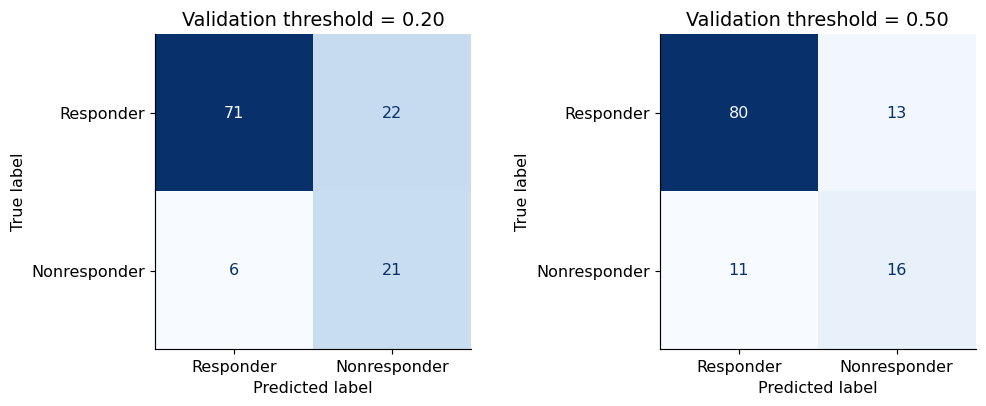

Always-Responder validation baseline: {'accuracy': 0.775, 'balanced_accuracy': 0.5, 'sensitivity / recall': 0.0, 'specificity': 1.0, 'precision': 0.0, 'F1': 0.0, 'TN': 93, 'FP': 0, 'FN': 27, 'TP': 0}


In [15]:
val_prob=chosen_model.predict_proba(X_val)[:,1]
THRESHOLDS=[.20,.35,.50,.65,.80]
metrics_by_threshold=pd.DataFrame([
    {'threshold':t,**metrics(y_val,(val_prob>=t).astype(int))}
    for t in THRESHOLDS])
display(metrics_by_threshold.round(3))

fig,axs=plt.subplots(1,2,figsize=(10,4))
show_cm(axs[0],y_val,(val_prob>=.20).astype(int),'Validation threshold = 0.20')
show_cm(axs[1],y_val,(val_prob>=.50).astype(int),'Validation threshold = 0.50')
finish('07_confusion_matrices')

print('Always-Responder validation baseline:',metrics(y_val,np.zeros_like(y_val)))

### 7a) Inspect the threshold tradeoff visually

Each point on this graph is calculated from the **same validation probabilities**; changing the threshold does not retrain the classifier. The 0.50 threshold is not magical, and the tradeoff depends on your scientific objective.

**Predict:** Why might `accuracy` stay respectable even when the classifier misses most nonresponders? What is the key distinction between **sensitivity** and **precision**?

**Your response:** **Prediction:** Accuracy is dominated by the majority responder class, so correctly labeling responders can hide missed nonresponders. Sensitivity asks what fraction of actual nonresponders were detected, TP/(TP+FN); precision asks what fraction of predicted nonresponders were truly nonresponders, TP/(TP+FP).

**After running:** At threshold 0.80, accuracy was 0.817 but sensitivity only 0.296, so 19 of 27 nonresponders were missed. The always-Responder baseline had accuracy 0.775 and sensitivity 0.000. These observations illustrate why accuracy can conceal poor minority-class detection.

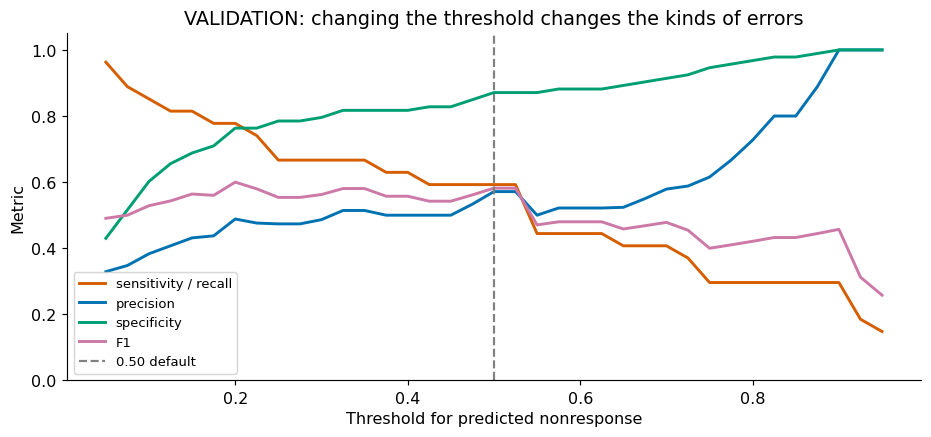

,partition,threshold,accuracy,balanced_accuracy,sensitivity / recall,specificity,precision,F1,TN,FP,FN,TP
0,TRAIN,0.5,0.903,0.817,0.662,0.971,0.869,0.752,272,8,27,53
1,TRAIN,0.2,0.850,0.841,0.825,0.857,0.623,0.710,240,40,14,66
2,VALIDATION,0.5,0.800,0.726,0.593,0.860,0.552,0.571,80,13,11,16
3,VALIDATION,0.2,0.767,0.771,0.778,0.763,0.488,0.600,71,22,6,21


In [16]:
ths=np.arange(.05,.951,.025)
sweep=pd.DataFrame([{'threshold':t,**metrics(y_val,(val_prob>=t).astype(int))}
                   for t in ths])
fig,ax=plt.subplots(figsize=(9,4.3))
for key,color in [('sensitivity / recall',ORANGE),('precision',BLUE),('specificity',GREEN),('F1',PURPLE)]:
    ax.plot(sweep.threshold,sweep[key],label=key,color=color,linewidth=2)
ax.axvline(.5,color='gray',ls='--',label='0.50 default')
ax.set(xlabel='Threshold for predicted nonresponse',ylabel='Metric',ylim=(0,1.05),
       title='VALIDATION: changing the threshold changes the kinds of errors')
ax.legend(loc='best',fontsize=9)
finish('07_threshold_tradeoff')
# Section 10 extension: use the selected TRAIN-fitted classifier at 0.50 vs 0.20.
# Prediction: lowering threshold increases/preserves recall and FP; precision may fall.
# No test features or labels are used and the final selection protocol is unchanged.
extension_result = pd.DataFrame([
    {'partition': label, 'threshold': t, **metrics(truth, (chosen_model.predict_proba(features)[:,1]>=t).astype(int))}
    for label,features,truth in [('TRAIN',X_train,y_train),('VALIDATION',X_val,y_val)]
    for t in [.50,.20]])
display(extension_result.round(3))


**Explain:** Copy TP, FP, FN, precision and sensitivity at thresholds **0.20** and **0.50** from the previous table. If the purpose were to **screen for likely nonresponse**, which might you prefer? If the purpose were to limit unnecessary treatment changes, which might you prefer? Explain in terms of errors, not just F1.

**Your response:** At threshold 0.20, TP = 21, FP = 22 and FN = 6; precision is 21/43 = 0.488 and sensitivity is 21/27 = 0.778. At 0.50, TP = 16, FP = 13 and FN = 11; precision is 16/29 = 0.552 and sensitivity is 16/27 = 0.593. For a screen prioritizing detection of likely nonresponse, 0.20 may be preferable because it misses five fewer nonresponders. For limiting unnecessary treatment changes among actual responders, 0.50 may be preferable because it creates nine fewer false alarms. The appropriate operating point depends on consequences and follow-up testing; F1 alone does not determine the biological decision.

## 8) ROC vs precision–recall: evaluating ranking across thresholds

The **ROC curve** plots **true positive rate (sensitivity)** against **false positive rate = 1 − specificity** at many thresholds. **ROC-AUC** measures the ability to rank nonresponders above responder ones (0.5 is chance-level ranking for a random score).

The **precision–recall (PR) curve** plots precision versus sensitivity. Its approximate no-skill **horizontal baseline equals the proportion of nonresponders**. **Average precision (AP)** is the stepwise-weighted summary of the PR curve; it is *not exactly* trapezoidal area under that curve. In an imbalanced dataset, PR often makes the burden of false-positive predictions more visible than ROC.

**Predict:** Suppose only ~20% of tumors are Nonresponders. If your classifier identifies most nonresponders but also flags many responder tumors, can its ROC curve still look fairly good while precision is mediocre? What baseline values would you expect for ROC-AUC and AP under random ranking?

**Your response:** **Prediction:** Yes. A relatively small false-positive rate can still represent many responders when responders are numerous, giving mediocre precision despite a reasonable ROC curve. Random ranking has expected ROC-AUC about 0.50 and AP approximately the nonresponder prevalence, about 0.20 in this example.

**After running:** The selected SVM had validation ROC-AUC 0.825, but precision was only 0.488 at threshold 0.20. The displayed PR baseline was 0.225, consistent with validation prevalence, while the ROC random-ranking reference was the diagonal with AUC 0.50. This illustrates the predicted distinction between favorable ranking and the reliability of positive calls.

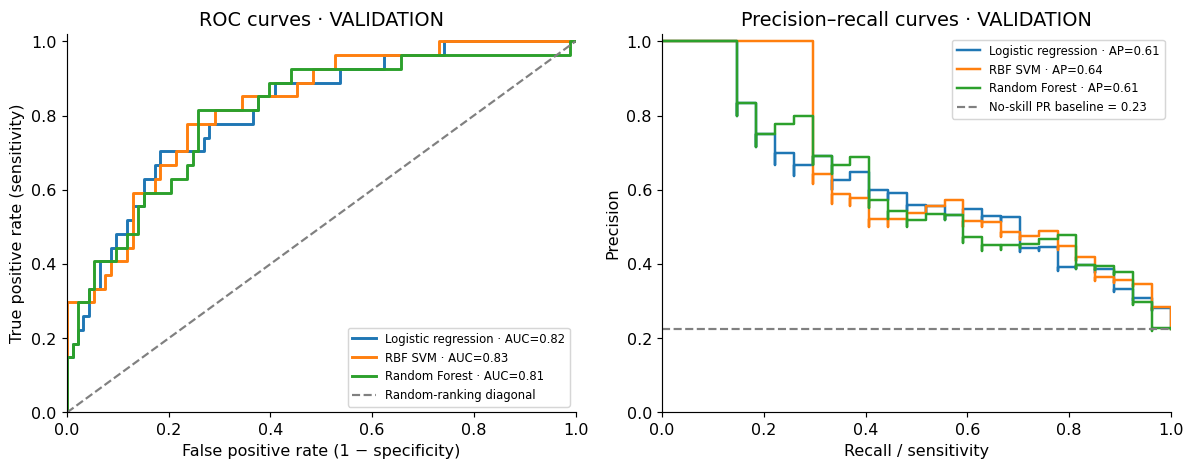

,Classifier,VALIDATION ROC-AUC,VALIDATION average precision
0,Logistic regression,0.816,0.606
1,RBF SVM,0.825,0.638
2,Random Forest,0.808,0.607


In [17]:
fig,axs=plt.subplots(1,2,figsize=(11.5,4.6))
pr_rows=[]
for name,grid in searches.items():
    proba=grid.best_estimator_.predict_proba(X_val)[:,1]
    fpr,tpr,_=roc_curve(y_val,proba)
    prec,rec,_=precision_recall_curve(y_val,proba)
    auc=roc_auc_score(y_val,proba)
    ap=average_precision_score(y_val,proba)
    axs[0].plot(fpr,tpr,linewidth=2,label=f'{name} · AUC={auc:.2f}')
    axs[1].step(rec,prec,where='post',linewidth=1.7,label=f'{name} · AP={ap:.2f}')
    pr_rows.append({'Classifier':name,'VALIDATION ROC-AUC':auc,'VALIDATION average precision':ap})
axs[0].plot([0,1],[0,1],ls='--',color='gray',label='Random-ranking diagonal')
axs[0].set(xlabel='False positive rate (1 − specificity)',ylabel='True positive rate (sensitivity)',
           title='ROC curves · VALIDATION',xlim=(0,1),ylim=(0,1.02))
axs[1].axhline(y_val.mean(),ls='--',color='gray',label=f'No-skill PR baseline = {y_val.mean():.2f}')
axs[1].set(xlabel='Recall / sensitivity',ylabel='Precision',title='Precision–recall curves · VALIDATION',
           xlim=(0,1),ylim=(0,1.02))
for ax in axs: ax.legend(fontsize=8,loc='best')
finish('08_roc_vs_precision_recall')
display(pd.DataFrame(pr_rows).round(3))

**Explain:** Identify the highest validation **ROC-AUC** and **average precision**. Does the best model by ROC-AUC necessarily have the best AP or highest F1 at 0.50? Report the **PR baseline** and explain why class prevalence matters for precision. Does either curve establish **calibration** of predicted probabilities?

**Your response:** RBF SVM had the highest validation ROC-AUC, 0.825, and average precision, 0.638. Logistic Regression had ROC-AUC 0.816 and AP 0.606; Random Forest had ROC-AUC 0.808 and AP 0.607. The same model happens to lead both rankings here, but ROC-AUC, AP and F1 at 0.50 measure different properties and need not rank models identically. ROC-AUC summarizes ordering across positive–negative pairs; AP emphasizes precision across recall levels; F1 also depends on a particular threshold. The no-skill PR baseline is 27/120 = 0.225. With fewer nonresponders, false alarms among the larger responder group can dominate positive predictions, reducing precision even at unchanged sensitivity and specificity. Neither ROC nor PR establishes calibration: that requires checking whether predicted probabilities agree with observed frequencies, for example using calibration plots and proper probability scores on independent data.

## 9) Lock the decision threshold; then open the TEST set **once**

The model family and hyperparameters were chosen by TRAIN-only cross-validation (Section 6). Now choose a threshold on VALIDATION using a fixed candidate list and **validation F1** as a *teaching* objective. In a real study, the threshold must reflect clinical/biological costs and ideally be specified in advance or tuned in an independent validation cohort.

**Do not change your model or threshold after you see the TEST result.** Trying many candidate thresholds can itself overfit the validation set, so the TEST set protects against optimistic selection.

**Predict:** If the held-out test F1 is lower than the validation F1, does that mean the code is wrong? Should you try 10 more thresholds **on the test data** to improve it?

**Your response:** **Prediction:** A lower test F1 would not by itself indicate incorrect code. Sampling variation and selection on validation data can make test performance lower. Trying more thresholds on the test data would compromise its independence; the chosen model and threshold should remain fixed.

**After running:** The locked threshold was 0.20. Test F1 was 0.487 versus validation F1 0.600, consistent with sampling variation and validation selection rather than proving an implementation error. The model, hyperparameters and threshold were left unchanged after this evaluation.

In [18]:
# Threshold is selected ONLY with validation samples, while the classifier was selected by TRAIN CV.
threshold_grid=np.round(np.arange(.10,.91,.05),2)
threshold_scores=pd.DataFrame([{
    'threshold':float(t),
    'validation_F1':f1_score(y_val,(val_prob>=t).astype(int),zero_division=0)}
    for t in threshold_grid])
chosen_threshold=float(threshold_scores.sort_values(
    ['validation_F1','threshold'],ascending=[False,True]).iloc[0]['threshold'])
chosen_validation_f1=float(threshold_scores['validation_F1'].max())
print('LOCKED MODEL:',chosen_name)
print('LOCKED THRESHOLD:',chosen_threshold)
print('VALIDATION F1:',round(chosen_validation_f1,3))
print('From this point forward, no further model or threshold tuning is permitted.')

LOCKED MODEL: RBF SVM
LOCKED THRESHOLD: 0.2
VALIDATION F1: 0.6
From this point forward, no further model or threshold tuning is permitted.


### Final held-out evaluation

This is the **first** point in the notebook at which we use the TEST labels. A discrepancy between validation and test performance is expected because of sampling variation and imperfect model selection.

HELD-OUT TEST · RBF SVM · threshold 0.2


,accuracy,balanced_accuracy,sensitivity / recall,specificity,precision,F1,TN,FP,FN,TP
0,0.667,0.68,0.704,0.656,0.373,0.487,61,32,8,19


TEST ROC-AUC: 0.802
TEST average precision: 0.702


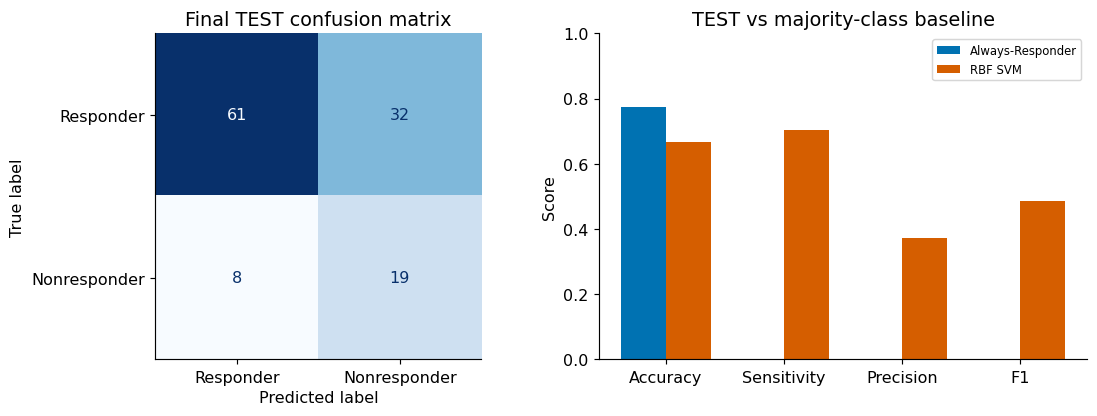

In [19]:
# One evaluation ONLY: do not use these results to retune.
test_probability=chosen_model.predict_proba(X_test)[:,1]
test_prediction=(test_probability>=chosen_threshold).astype(int)
test_metrics=metrics(y_test,test_prediction)
print('HELD-OUT TEST ·',chosen_name,'· threshold',chosen_threshold)
display(pd.DataFrame([test_metrics]).round(3))
print('TEST ROC-AUC:',round(roc_auc_score(y_test,test_probability),3))
print('TEST average precision:',round(average_precision_score(y_test,test_probability),3))

fig,axs=plt.subplots(1,2,figsize=(11,4.1))
show_cm(axs[0],y_test,test_prediction,'Final TEST confusion matrix')
baseline=metrics(y_test,np.zeros_like(y_test))
keys=['accuracy','sensitivity / recall','precision','F1']
xx=np.arange(len(keys))
axs[1].bar(xx-.19,[baseline[k] for k in keys],width=.38,color=BLUE,label='Always-Responder')
axs[1].bar(xx+.19,[test_metrics[k] for k in keys],width=.38,color=ORANGE,label=chosen_name)
axs[1].set_xticks(xx,['Accuracy','Sensitivity','Precision','F1'])
axs[1].set(ylabel='Score',ylim=(0,1),title='TEST vs majority-class baseline')
axs[1].legend(fontsize=8)
finish('09_final_test')

pd.DataFrame({'sample_id':[f'Tumor_{i+1:03d}' for i in test_idx],
              'actual_nonresponder':y_test,'predicted_probability':test_probability,
              'predicted_nonresponder':test_prediction}).to_csv(
                  OUT/'held_out_test_predictions.csv',index=False)

**Explain:** Record the chosen classifier, hyperparameters, threshold, test **TN/FP/FN/TP**, **sensitivity**, **precision**, **F1**, and **ROC-AUC**. Why would choosing a different model after this output compromise the interpretation of held-out performance? What external validation would be needed before using an assay on real tumors?

**Your response:** The locked classifier was an RBF SVM with C = 0.1 and gamma = 0.001, preceded by training-only StandardScaler preprocessing; probability estimation used random_state = 42. The validation-selected threshold was 0.20, with validation F1 = 0.600. On 120 held-out tumors, TN = 61, FP = 32, FN = 8 and TP = 19. Sensitivity was 19/27 = 0.704, precision was 19/51 = 0.373, F1 was 0.487, ROC-AUC was 0.802 and AP was 0.702. Accuracy was 0.667, below the always-Responder baseline of 0.775, but the model detected 19 nonresponders whereas the baseline detected none. Changing models or thresholds after viewing these results would make the test labels part of selection, compromising the interpretation of this estimate as held-out performance. Before use on real tumors, the frozen assay, preprocessing, classifier and threshold would require independent patient-level validation across laboratories, batches and relevant clinical populations, followed by prospective evaluation of calibration, error consequences and usefulness.

## 10) Interpreting the biology — not just the score

In our simulation, **two latent biological processes** influence both gene expression and tumor responsiveness to treatment, while the technical batch influences a different subset of genes. We know this *only because we constructed the data*. In a real omics study, observed associations alone cannot tell us which gene(s) is/are causal or whether batch, clinical factors, ancestry, repeated samples, or other confounders matter.

**Review:**
- **Clustering vs classification:** PCA/UMAP/t-SNE reveal patterns without labels. Classification predicts **known** response labels. Neither proves that a cluster is a distinct biological subtype.
- **Evaluation:** Training performance is not generalization. CV and validation are for model/threshold selection; the untouched test set estimates performance after decisions are locked.
- **Biological study design:** Patient-level splits prevent replicate leakage. Technical batch, study site, different prevalence and treatment context can all change observed performance.
- **Interpretability:** Logistic Regression coefficients and Random Forest importance reflect fitted *associations*, not gene function or causality.

### Exit ticket — answer all five
1. Explain the biological interpretation of a false negative and false positive when nonresponse is the positive class.
2. Explain how `C` and `gamma` affect an RBF SVM and why CV should select hyperparameters.
3. Why can ROC-AUC look respectable for an imbalanced outcome even when precision is not clinically useful?
4. Does good held-out (test) prediction establish that expression differences cause nonresponse? Name one experimental or external-validation test that would strengthen a biological conclusion.

**Your responses:**

1. With Nonresponder = 1, a false negative is an actual nonresponder predicted to respond; acting on this result could expose a patient to an ineffective treatment. A false positive is an actual responder predicted not to respond; acting on it could withhold an effective treatment or trigger an unnecessary change. These are distinct biological consequences, and their relative costs depend on the intended use.

2. C controls the penalty for margin violations: a smaller C imposes stronger regularization, whereas a larger C encourages fitting the training labels more closely. Gamma controls how quickly RBF similarity decays with distance; large gamma gives each point a narrow influence and permits more local boundaries. These hyperparameters must be selected using training-only cross-validation because improved training fit does not guarantee generalization. Scaling belongs inside each fold so its held-out samples do not influence preprocessing.

3. ROC-AUC evaluates ranking through sensitivity and false-positive rate, whose denominator includes all actual responders. When responders greatly outnumber nonresponders, even a moderate false-positive rate can produce enough false alarms to make precision low. Precision depends on prevalence as well as sensitivity and specificity, so a respectable ROC-AUC does not guarantee useful positive predictions. Precision–recall curves and operating-point confusion counts expose that burden more directly.

4. Good held-out prediction establishes evidence of predictive association in the sampled setting, not that expression differences cause nonresponse. Expression may be a downstream marker of latent processes or correlated with clinical and technical factors. Perturbing a candidate gene in an appropriate tumor model and testing the therapy response, with controls and replication, would strengthen a causal hypothesis. Separately, a frozen assay and decision rule should be tested in an independent patient cohort and laboratory before claims about clinical transfer.

**AI assisted extension / code evaluation:** Ask an AI assistant to suggest one change to an SVM `C`/`gamma` choice, RF leaf-size setting, or classification threshold. First predict how that change should affect TRAIN vs VALIDATION F1 or sensitivity vs precision. Implement one variation using *only training/validation*, and verify the outcome. Do not use TEST data to justify new choices. **In your response, include AI Tool/prompt, prediction, code change, output checked, conclusion.**

5. **Tool and prompt:** ChatGPT/Codex: “Using only the existing training-fitted classifier and training/validation data, compare thresholds 0.50 and 0.20. Report sensitivity, precision, F1 and confusion counts without touching test data or changing the final selection procedure.” **Prediction recorded before execution:** Lowering the threshold should increase or preserve sensitivity and false positives; precision may decline, depending on the newly flagged tumors. **Code change:** The comparison is appended to the existing Section 7a code cell, before test evaluation; it uses `chosen_model.predict_proba(X_train)` and `chosen_model.predict_proba(X_val)` with fixed thresholds. The test set is excluded from this extension.


**Extension output checked and conclusion:** In the training set, lowering the threshold from 0.50 to 0.20 increased sensitivity from 0.662 to 0.825, reduced precision from 0.869 to 0.623, and reduced F1 from 0.752 to 0.710; false positives increased from 8 to 40. In validation, sensitivity rose from 0.593 to 0.778, precision fell from 0.552 to 0.488, and F1 rose from 0.571 to 0.600; false positives increased from 13 to 22. This supports the predicted sensitivity–precision tradeoff and shows why improving training F1 is not the objective for selecting an operating threshold. The comparison uses fixed probabilities from the existing training-fitted model, not retraining. It was executed in Section 7a before opening the test set; the predefined validation-only threshold-selection rule in Section 9 was retained. Test results played no role in this extension. The change can be useful when missed nonresponders are costly, but the larger false-positive burden must also be considered.


### References and saved outputs

- [scikit-learn: Pipelines](https://scikit-learn.org/stable/modules/compose.html#pipeline)
- [scikit-learn: Cross-validation and GridSearchCV](https://scikit-learn.org/stable/modules/cross_validation.html)
- [scikit-learn: SVM documentation](https://scikit-learn.org/stable/modules/svm.html)
- [scikit-learn: Random Forest](https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees)
- [scikit-learn: Precision–recall](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html)

Figures and CSVs are saved to `classifier_outputs` during execution. The `.ipynb` file itself stores code and your written answers. The optional cell below packages figures and CSVs separately.

In [20]:
import shutil
archive=shutil.make_archive('classifier_outputs','zip',OUT)
print('Created:',archive)
# For Colab downloads, uncomment:
# from google.colab import files
# files.download(archive)

Created: /private/tmp/module10_submission/classifier_outputs.zip
